# A.3 Reference design — Four-qubit multiplexed readout

A four-transmon chip with frequency-multiplexed dispersive readout: four resonators of stepped length share one coplanar-waveguide feedline — the standard readout architecture for small superconducting processors.

> **Reference design — attribution.** Adapted, with attribution, from the open-source [SQDMetal](https://github.com/sqdlab/SQDMetal) project (Apache-2.0) and its benchmark devices in D. Sommers, P. Pakkiam, Z. Degnan, C.-C. Chiu, D. Gautam, Y.-H. Chen, and A. Fedorov, *"Open-Source Highly Parallel Electromagnetic Simulations for Superconducting Circuits,"* [arXiv:2511.01220](https://arxiv.org/abs/2511.01220) (2025). Re-implemented here with stock Quantum Metal components.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/qiskit-community/qiskit-metal/blob/main/docs/tut/full-design-examples/A.3-Four-qubit-multiplexed-readout.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/qiskit-community/qiskit-metal/main?labpath=docs%2Ftut%2Ffull-design-examples%2FA.3-Four-qubit-multiplexed-readout.ipynb)

> 💡 **Running in Colab or Binder?** Skip the desktop GUI install — the cell below grabs the lite (no-Qt) wheel, and `qm.gui(design)` auto-picks an inline matplotlib viewer with the same API as the desktop `MetalGUI`.

In [1]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
# !pip install -q quantum-metal

In [2]:
import qiskit_metal as qm
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.pathfinder import RoutePathfinder
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond

design = designs.DesignPlanar()
design.overwrite_enabled = True

# The default die is 9mm x 6mm; the launchpads below sit outside it.
design.chips.main.size.size_x = "16mm"
design.chips.main.size.size_y = "9mm"

In [3]:
def feed(a, ap, b, bp, name):
    """Auto-route a coplanar-waveguide feedline segment between two pins."""
    RoutePathfinder(
        design,
        name,
        options=dict(
            fillet="90um",
            pin_inputs=Dict(
                start_pin=Dict(component=a, pin=ap), end_pin=Dict(component=b, pin=bp)
            ),
        ),
    )


def readout(clt, q, name, length):
    """Meandered lambda/4 readout resonator: coupled-line tee -> qubit readout pad."""
    RouteMeander(
        design,
        name,
        options=dict(
            fillet="90um",
            total_length=length,
            lead=Dict(start_straight="100um", end_straight="100um"),
            pin_inputs=Dict(
                start_pin=Dict(component=clt, pin="second_end"),
                end_pin=Dict(component=q, pin="readout"),
            ),
        ),
    )

## 1. Four transmons + four readout tees

Four transmons in a row; above each, a coupled-line tee on a single shared feedline.

In [4]:
xs = [-4.5, -1.5, 1.5, 4.5]
for i, x in enumerate(xs, 1):
    TransmonPocket(
        design,
        f"Q{i}",
        options=dict(
            pos_x=f"{x}mm",
            pos_y="-1.8mm",
            pad_width="425um",
            pocket_height="650um",
            connection_pads=dict(readout=dict(loc_W=1, loc_H=1)),
        ),
    )
    CoupledLineTee(
        design,
        f"clt{i}",
        options=dict(
            pos_x=f"{x}mm",
            pos_y="1.8mm",
            coupling_length="350um",
            down_length="300um",
            fillet="90um",
            open_termination=False,
        ),
    )

## 2. One shared feedline through all four tees

In [5]:
LaunchpadWirebond(
    design, "LPin", options=dict(pos_x="-7.5mm", pos_y="1.8mm", orientation="0")
)
LaunchpadWirebond(
    design, "LPout", options=dict(pos_x="7.5mm", pos_y="1.8mm", orientation="180")
)
feed("LPin", "tie", "clt1", "prime_start", "f0")
for i in range(1, 4):
    feed(f"clt{i}", "prime_end", f"clt{i + 1}", "prime_start", f"f{i}")
feed("clt4", "prime_end", "LPout", "tie", "f4")

## 3. Four frequency-multiplexed readout resonators

Stepped meander lengths -> distinct readout frequencies on the one feedline (printed below).

In [6]:
for i, L in zip(range(1, 5), ["6.8mm", "7.0mm", "7.2mm", "7.4mm"]):
    readout(f"clt{i}", f"Q{i}", f"read{i}", L)

04:07PM 23s WARNING [check_lengths]: For path table, component=read1, key=trace has short segments that could cause issues with fillet. Values in (1-2)  are index(es) in shapely geometry.


04:07PM 23s WARNING [check_lengths]: For path table, component=read1, key=cut has short segments that could cause issues with fillet. Values in (1-2)  are index(es) in shapely geometry.


### Resonator frequencies

With `open_termination=False` the resonator end at the tee is shorted to ground, so the tee couples to the resonator mainly inductively, at its current antinode (see the `CoupledLineTee` docstring). The λ/4 resonator is the tee's coupled arm (`second_cpw`), the meander and the qubit's readout pad stub (`readout_wire`) together: `total_length` covers the meander only, about 89 % of the line. The cell below prints the bare λ/4 frequency of each resonator and the meander length for a 7 GHz readout. With the lengths drawn here the readout resonators sit near 3.7-4.0 GHz, below the transmons (about 5.5 GHz for this pocket at L_J = 12.31 nH, tutorial 4.11); a readout above the qubits needs meanders of about 3.5 mm, and at these positions the shorter meander needs its fillet, spacing or the qubit position adjusted to keep `validate()` clean. Qubit and pad capacitances pull the actual frequencies further down.

In [7]:
import numpy as np
import pandas as pd
from qiskit_metal.analyses.em.cpw_calculations import guided_wavelength

C_LIGHT = 299792458.0


def drawn_length(component, name):
    """Length (mm) of one path of a component, filleted corners counted as arcs."""
    table = design.qgeometry.tables["path"]
    row = table[
        (table.component == design.components[component].id) & (table.name == name)
    ].iloc[0]
    fillet = 0.0 if pd.isna(row.fillet) else float(row.fillet)
    corners = max(len(row.geometry.coords) - 2, 0)
    return row.geometry.length - corners * (2 - np.pi / 2) * fillet


def sqrt_eps_eff(f_ghz):
    """10 um / 6 um CPW (the design defaults) on 750 um silicon, 200 nm film."""
    return guided_wavelength(f_ghz * 1e9, 10e-6, 6e-6, 750e-6, 200e-9)[1]


def resonator_summary(clt, q, res, f_target=7.0):
    """Bare lambda/4 frequency of the line tee arm + meander + qubit pad stub,
    and the meander length that would put it at f_target (GHz)."""
    extra = drawn_length(clt, "second_cpw") + drawn_length(q, "readout_wire")
    line = design.components[res].length + extra  # mm
    f_bare = C_LIGHT / (4 * line * 1e-3 * sqrt_eps_eff(6.0)) / 1e9
    meander_target = C_LIGHT / (4 * f_target * 1e9 * sqrt_eps_eff(f_target)) * 1e3 - extra
    print(
        f"{res}: meander {line - extra:.3f} mm + tee arm and pad stub {extra:.3f} mm"
        f" -> bare lambda/4 {f_bare:.2f} GHz; meander for {f_target} GHz: {meander_target:.2f} mm"
    )


for clt, q, res in [(f"clt{i}", f"Q{i}", f"read{i}") for i in range(1, 5)]:
    resonator_summary(clt, q, res)

read1: meander 6.800 mm + tee arm and pad stub 0.846 mm -> bare lambda/4 3.98 GHz; meander for 7.0 GHz: 3.50 mm
read2: meander 7.000 mm + tee arm and pad stub 0.846 mm -> bare lambda/4 3.88 GHz; meander for 7.0 GHz: 3.50 mm
read3: meander 7.200 mm + tee arm and pad stub 0.846 mm -> bare lambda/4 3.78 GHz; meander for 7.0 GHz: 3.50 mm
read4: meander 7.400 mm + tee arm and pad stub 0.846 mm -> bare lambda/4 3.69 GHz; meander for 7.0 GHz: 3.50 mm


## 4. Visualize

## Next steps

- **Inspect** the design tree: `design.components.keys()` and `design.qgeometry.tables`.
- **Export GDS** for fabrication: `design.renderers.gds.export_to_gds('chip.gds')` (Quantum Metal uses the modern `gdstk` backend).
- **Simulate**: render to Ansys HFSS/Q3D (the validation gold standard) or to the open-source FEM path (Gmsh + Elmer today; AWS Palace on the roadmap) to extract eigenmodes, *Q*, and the capacitance matrix.
- **Tweak**: every dimension above is a parameter — change `total_length` to retune a resonator (it is only the meander: the λ/4 line also includes the tee's coupled arm and the qubit's pad stub, about 0.85 mm here; `resonator_summary` gives the meander for a target frequency), or `pos_x`/`pos_y` to relayout.

In [8]:
design.components.keys()

['Q1',
 'clt1',
 'Q2',
 'clt2',
 'Q3',
 'clt3',
 'Q4',
 'clt4',
 'LPin',
 'LPout',
 'f0',
 'f1',
 'f2',
 'f3',
 'f4',
 'read1',
 'read2',
 'read3',
 'read4']

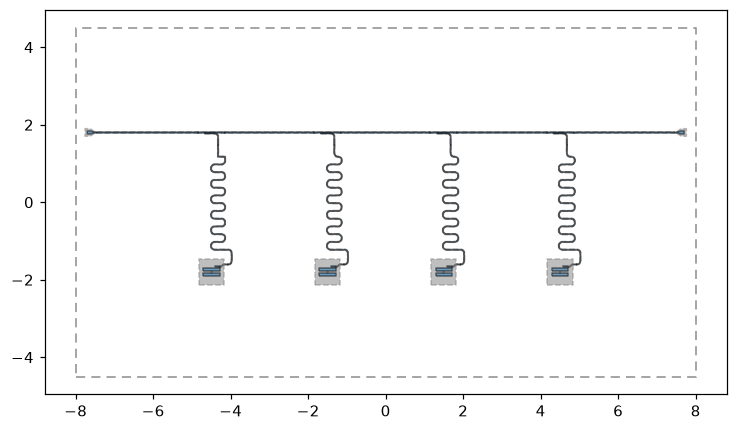

In [9]:
fig = qm.view(design)
qm.show_inline(fig)